## Comparação das mensagens: probabilidades vs média e std por âncora (MC Dropout)

## Nova experiência — média e desvio-padrão por âncora com MC Dropout

A proposta escolhida envia uma média e um desvio-padrão **por âncora**, calculados sobre 20 previsões estocásticas da **probabilidade de anomalia da mesma âncora**. A média continua associada à classe anomalia; `p(normal) = 1 − média`. O desvio-padrão mede variabilidade das previsões, não é calculado entre as duas classes nem entre âncoras diferentes. A opção anterior de dois números por cliente foi interrompida e preservada em `artifacts/softlabels_moments_history/client_wide_v1/`; não é misturada nesta experiência.

| Representação por cliente/ronda | Números float32 | Payload sem contagem de fit | Objetivo |
|---|---:|---:|---|
| Atual: normal e anomalia por âncora | 64 | 256 B | Referência determinística |
| Só anomalia por âncora | 32 | 128 B | Eliminar redundância binária |
| MC Dropout: só média de anomalia por âncora | 32 | 128 B | Isolar o efeito de repetir previsões |
| MC Dropout: média e std de anomalia por âncora | 64 | 256 B | Usar também a variabilidade na aprendizagem |

**Exemplo:** previsões de anomalia `[0,80; 0,85; 0,90]` na mesma âncora dão média 0,85 e std aproximadamente 0,041. O servidor associa essa âncora a `[normal=0,15; anomalia=0,85]`, mantendo a informação de classe. Isto não garante a mesma decisão de uma única previsão determinística; usa a previsão média. Também não se preserva toda a distribuição com apenas dois momentos.

**MC Dropout:** o professor faz 20 passagens com as camadas Dropout ativas. As restantes camadas, incluindo BatchNorm, permanecem em avaliação; as âncoras não atualizam as suas estatísticas. O estado do gerador aleatório é restaurado após as passagens, e as duas variantes MC usam as mesmas sementes de amostragem. O aumento de cálculo é contabilizado. [Fundamento de MC Dropout — Gal e Ghahramani, 2016](https://proceedings.mlr.press/v48/gal16.html).

**Agregação por âncora:** `mu = sum(w_i*mu_i)` e `var = sum(w_i*(sigma_i²+mu_i²)) − mu²`. Esta variância da mistura inclui a variabilidade dentro de cada professor e o desacordo entre professores. Não é a variância estatística da média do ensemble, nem uma medida de confiança calibrada.

**Uso do std no aluno:** a média fornece o alvo suave `[1−mu, mu]`. Na variante média+std, a entropia cruzada de cada âncora é ponderada por `1/(1+4*var)`, normalizada para média 1 entre as 32 âncoras. A constante 4 vem do limite de variância 1/4 de uma probabilidade em [0,1]; a regra é fixada antes de avaliar os resultados, sem ajustar ao holdout. A variante só com médias MC usa a mesma entropia cruzada sem essa ponderação, permitindo separar o efeito das previsões repetidas do efeito do std.

**Desenho e critérios:** candidata A (AE+CNN no Icentia e MobileNetV2 no PhysioNet), CNN1D global, mesmos dados agrupados, cinco seeds 2031–2035, três rondas e dez épocas locais. Pesos de fit 72,73%/27,27%. PR-AUC local no holdout do próprio cliente é principal; PR-AUC global nos mesmos holdouts é secundário. Usa-se a última ronda fixa, médias ponderadas e diferenças pareadas. Dev é secundário, test reservado e holdout exploratório. As referências concluídas só são reutilizadas quando compatíveis e novamente validadas.

Esta ablação é **sem SA/LDP**, para isolar a representação. Para uma futura SA, os clientes poderiam preparar momentos aditivos (`mu` e `sigma²+mu²`) em vez de somar desvios-padrão diretamente. Média+std por âncora mantém os mesmos 64 valores da referência, logo não se presume poupança de bytes; a vantagem potencial é informação sobre variabilidade. Nenhuma variante demonstra maior privacidade ou menor consumo energético apenas pelo formato da mensagem. O download da CNN1D global é mantido e contabilizado nas quatro variantes.


{'status': 'complete', 'validated_conditions': 20, 'reused_baselines': 5, 'signature': 'ce19a4b15f1274b85aa469868ed01580d9def9b65dd9ca23014b825799b65973'}

**20/20 condições completas e validadas.** `n` mostra as seeds realmente disponíveis; resultados incompletos não permitem uma decisão final.

{'representation': 'anomaly32', 'status': 'running', 'kind': 'Softlabels', 'condition': 'plain', 'seed': 2035, 'round': 3, 'signature': 'ce19a4b15f1274b85aa469868ed01580d9def9b65dd9ca23014b825799b65973'}

{'representation': 'mc_mean32', 'status': 'running', 'kind': 'Softlabels', 'condition': 'plain', 'seed': 2035, 'round': 3, 'signature': 'ce19a4b15f1274b85aa469868ed01580d9def9b65dd9ca23014b825799b65973'}

{'representation': 'mc_meanstd64', 'status': 'running', 'kind': 'Softlabels', 'condition': 'plain', 'seed': 2035, 'round': 3, 'signature': 'ce19a4b15f1274b85aa469868ed01580d9def9b65dd9ca23014b825799b65973'}

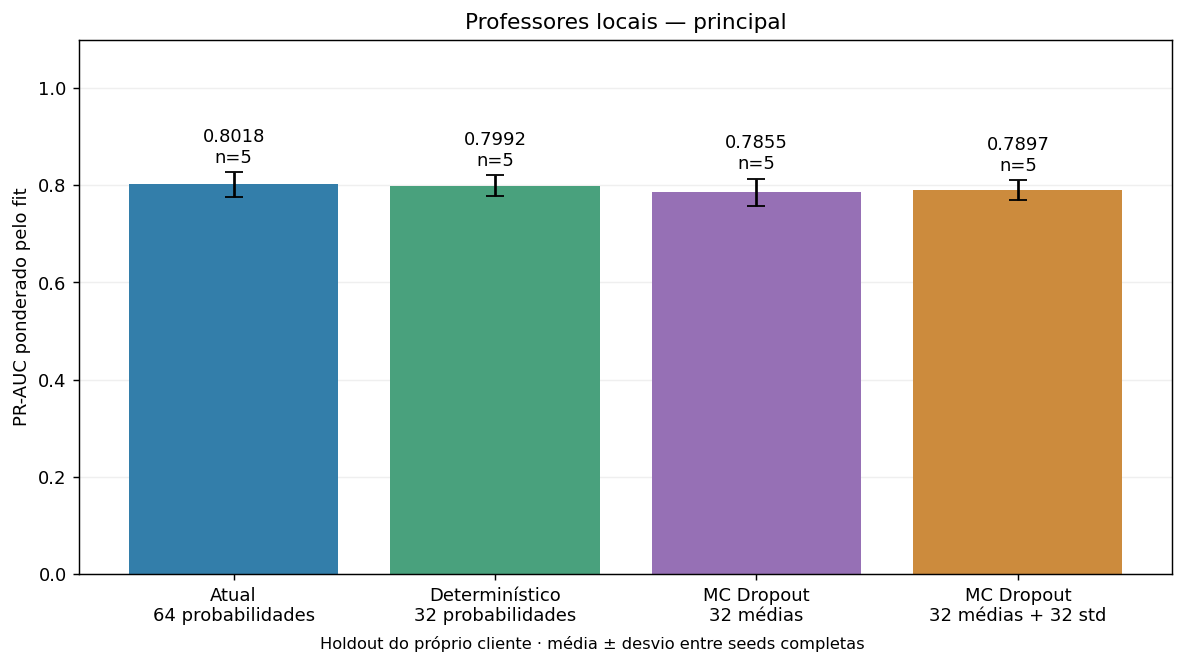

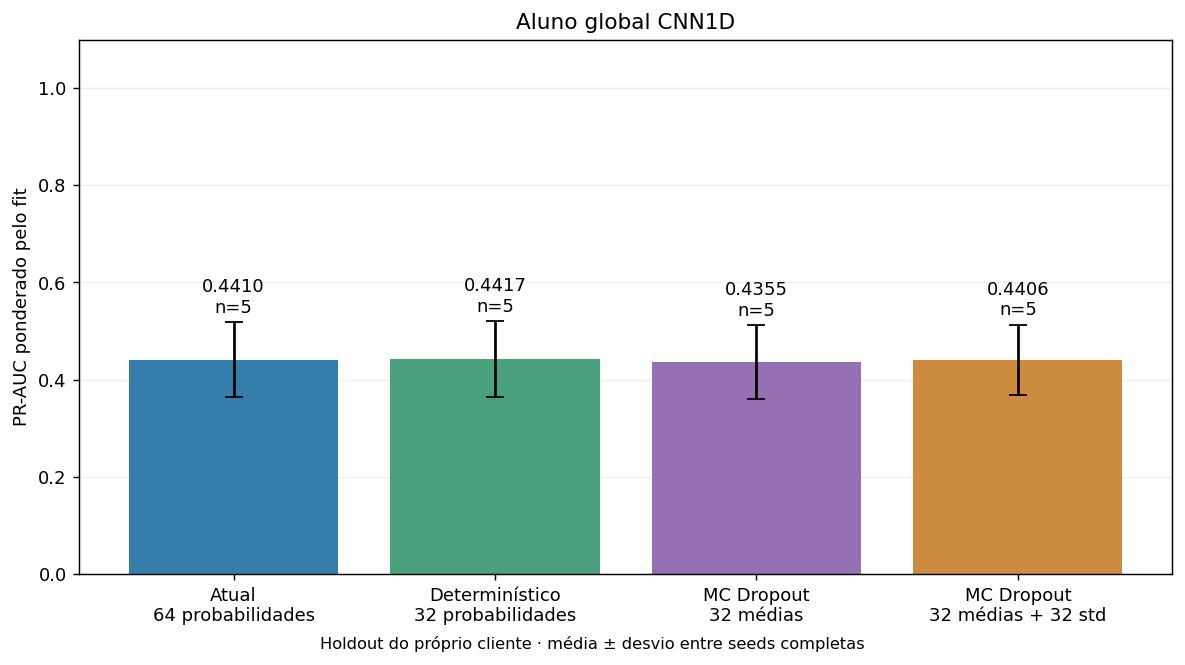

mode,seed,role,pr_auc_ap,valid_clients,total_clients,fit_coverage
probabilities64,2031,global,0.452283,22,22,1.0
probabilities64,2031,local,0.788336,22,22,1.0
probabilities64,2032,global,0.504633,22,22,1.0
probabilities64,2032,local,0.788149,22,22,1.0
probabilities64,2033,global,0.309112,22,22,1.0
probabilities64,2033,local,0.844688,22,22,1.0
probabilities64,2034,global,0.485029,22,22,1.0
probabilities64,2034,local,0.782420,22,22,1.0
probabilities64,2035,global,0.453975,22,22,1.0
probabilities64,2035,local,0.805574,22,22,1.0


### Comunicação média por cliente no ciclo de três rondas — KiB

upload_bytes,download_bytes,total_bytes
0.761719,318.828125,319.589844
0.386719,318.828125,319.214844
0.386719,318.828125,319.214844
0.761719,318.828125,319.589844


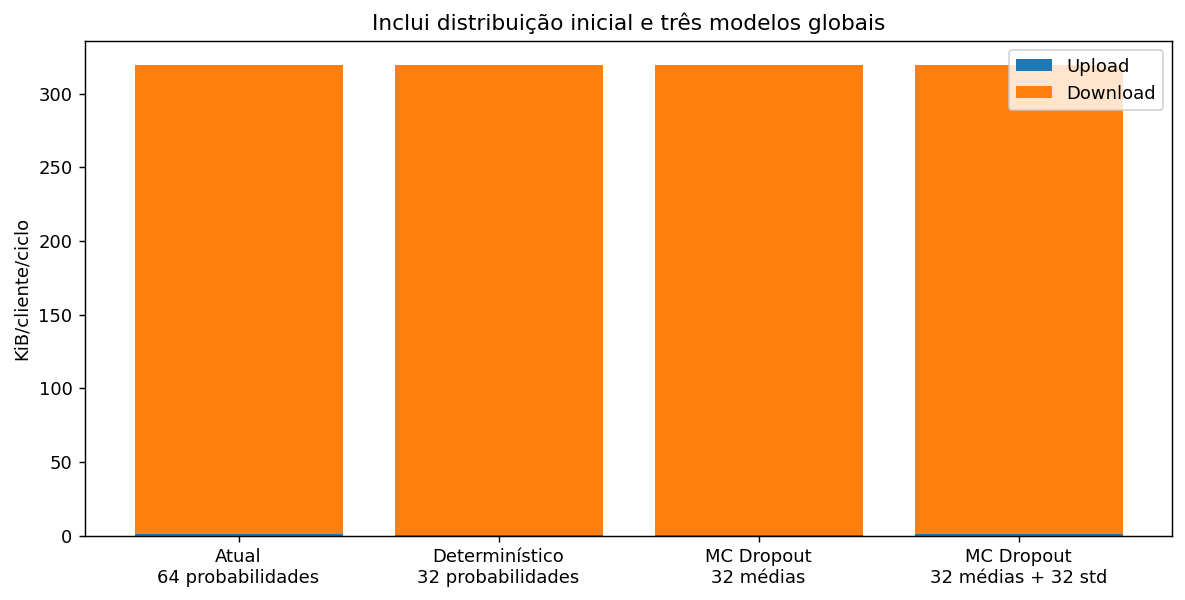

mode,seed,role,delta_vs_current
anomaly32,2031,global,0.007352
anomaly32,2031,local,0.000887
anomaly32,2032,global,-0.003082
anomaly32,2032,local,-0.006583
anomaly32,2033,global,-0.001850
anomaly32,2033,local,-0.007842
anomaly32,2034,global,0.008382
anomaly32,2034,local,0.011239
anomaly32,2035,global,-0.007468
anomaly32,2035,local,-0.010695


### Comparação concluída

As quatro representações foram avaliadas nas mesmas cinco seeds. A leitura principal é o PR-AUC local e a diferença pareada; o PR-AUC global e os bytes mostram o compromisso. A variante MC média+std mantém a identidade das âncoras e usa o mesmo payload de 64 valores da referência. A variante de 32 valores reduz o payload em 50% com equivalência matemática binária; não se deve atribuir significado estatístico a pequenas diferenças numéricas sem análise adicional.

role,global,local
,0.441673,0.799234
,0.435518,0.785467
,0.440621,0.789740
,0.441006,0.801833


In [1]:
from pathlib import Path
import sys
root=Path.cwd().resolve()
while not (root/'requirements.txt').exists() and root!=root.parent: root=root.parent
sys.path.insert(0,str(root))
from support.softlabels_moments_report import render
render()